# 05 — A1: Uji Ketahanan Noise & Evaluasi Subject-Independent

**Divisi:** A1 (Data & Praproses)
**Referensi:** Kar et al. (2021), IET Image Processing 15(7):1471–1483
— bagian 5.5 (noise Gaussian) dan bagian 3 (dataset CK+).

Notebook ini mendokumentasikan dua pekerjaan Minggu 14:

1. **Artefak citra ber-noise Gaussian** (variansi 0,01–0,1) sebagai bahan uji
   ketahanan model. Artefak inilah yang nanti diekstrak ulang fiturnya oleh A2
   dan dievaluasi oleh A3.
2. **Evaluasi subject-independent**, yaitu membandingkan akurasi ketika data
   dibagi acak (protokol A3) versus ketika subjek benar-benar dipisah.

> Catatan penting: dataset dan hasil di proyek ini **tidak** disamakan dengan
> jurnal. CK+ kita berisi 981 citra (327 sekuens × 3 frame) dan 7 kelas,
> sedangkan jurnal memakai 450 citra puncak dan 8 kelas. Angka jurnal hanya
> dipakai sebagai kolom pembanding.


## 1. Setup

In [15]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd


def _find_repo_root(start: Path) -> Path:
    """Telusuri ke atas sampai menemukan config.yaml (tahan dipindah folder)."""
    for candidate in [start, *start.parents]:
        if (candidate / "config.yaml").exists():
            return candidate
    raise RuntimeError(f"config.yaml tidak ditemukan dari {start}")


repo_root = _find_repo_root(Path.cwd().resolve())

# Modul .py berada di research/<divisi>/
for sub in ("a1-data-preprocessing", "a2-feature-engineering", "a3-model-optimization"):
    p = str(repo_root / "research" / sub)
    if p not in sys.path:
        sys.path.insert(0, p)

from baseline import load_config, resolve_path

config = load_config(repo_root / "config.yaml")
print("repo_root :", repo_root)
print("proyek    :", config["project"]["name"])
print("seed      :", config["project"]["random_seed"])

repo_root : D:\Semester5\pcvk\tugas_akhir
proyek    : TA-PCVK
seed      : 42


## 2. Teori singkat: mengapa noise Gaussian?

Jurnal bagian 5.5 menguji ketahanan sistem dengan menambahkan *random Gaussian
noise* bervariansi antara **0,01 dan 0,1**, lalu mengukur kembali Sen/Spe/Acc.

Noise ditambahkan pada **ruang intensitas [0, 1]** (bukan pada nilai piksel
0–255), sehingga standar deviasi yang diberikan adalah `sigma = sqrt(variance)`:

| Variansi | σ | Arti praktis |
|---|---|---|
| 0,01 | 0,10 | noise ±10% dari rentang intensitas |
| 0,02 | 0,141 | |
| 0,05 | 0,224 | |
| 0,10 | 0,316 | noise sangat kasar |

Citra hasil penambahan noise dikembalikan ke `uint8` agar A2 memakai jalur
ekstraksi fitur yang sama persis dengan data bersih.


## 3. Bangun artefak citra ber-noise

In [16]:
from noise import (
    DEFAULT_VARIANCES,
    add_gaussian_noise,
    build_noise_artifacts,
    load_noise_artifact,
    noise_statistics,
)

# Bangun (atau pakai ulang) seluruh artefak: CK+ & JAFFE x 4 variansi
written = build_noise_artifacts(config, variances=DEFAULT_VARIANCES)
print(f"\n{len(written)} artefak tersedia.")

[noise] ck: 981 citra, 7 kelas
  [skip] ck_noise_v0.01.npz sudah ada
  [skip] ck_noise_v0.02.npz sudah ada
  [skip] ck_noise_v0.05.npz sudah ada
  [skip] ck_noise_v0.10.npz sudah ada
[noise] jaffe: 213 citra, 7 kelas
  [skip] jaffe_noise_v0.01.npz sudah ada
  [skip] jaffe_noise_v0.02.npz sudah ada
  [skip] jaffe_noise_v0.05.npz sudah ada
  [skip] jaffe_noise_v0.10.npz sudah ada

8 artefak tersedia.


## 4. Verifikasi: σ teori vs σ empiris

In [17]:
rows = []
for key in ("ck", "jaffe"):
    clean = np.load(resolve_path(config, config["paths"][f"{key}_preprocessed"]), allow_pickle=True)["X"]
    for variance in DEFAULT_VARIANCES:
        art = load_noise_artifact(
            resolve_path(config, config["paths"]["a1_noise_dir"]) / f"{key}_noise_v{variance:.2f}.npz"
        )
        stats = noise_statistics(clean, art["X"])
        rows.append(
            {
                "Dataset": key.upper(),
                "Variansi": variance,
                "Sigma teori": round(float(np.sqrt(variance)), 4),
                "Sigma empiris": round(stats["empirical_std"], 4),
                "Max |diff|": round(stats["max_abs_diff"], 3),
            }
        )

df_noise = pd.DataFrame(rows)
df_noise

,Dataset,Variansi,Sigma teori,Sigma empiris,Max |diff|
0,CK,0.01,0.1000,0.0936,0.529
1,CK,0.02,0.1414,0.1293,0.753
2,CK,0.05,0.2236,0.1941,1.000
3,CK,0.10,0.3162,0.2566,1.000
4,JAFFE,0.01,0.1000,0.0948,0.518
5,JAFFE,0.02,0.1414,0.1306,0.718
6,JAFFE,0.05,0.2236,0.1954,0.980
7,JAFFE,0.10,0.3162,0.2578,1.000


**Mengapa σ empiris sedikit lebih kecil?** Dua sebab: (1) nilai
intensitas di-clip ke [0, 1] sehingga noise yang menjauh dari rentang hilang,
dan (2) kuantisasi ke 256 level (`uint8`) membulatkan sebagian variasi.
Semakin besar variansi, semakin besar pula bagian yang ter-clip — persis
terlihat pada tabel di atas.


## 5. Visual: citra bersih vs ber-noise

C:\Users\Zuhdi\AppData\Local\Temp\ipykernel_35888\2914671184.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


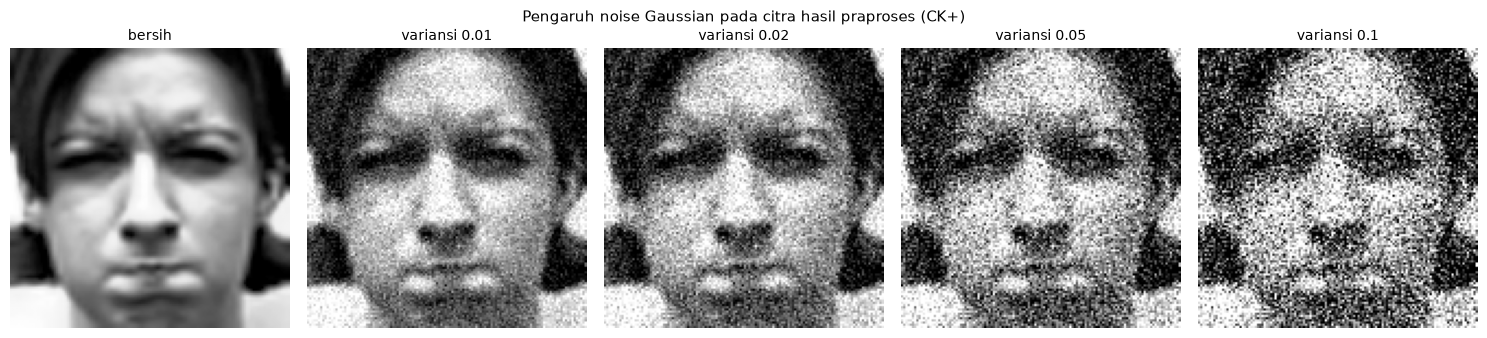

In [18]:
import matplotlib.pyplot as plt

clean = np.load(resolve_path(config, config["paths"]["ck_preprocessed"]), allow_pickle=True)["X"]
idx = 0  # satu contoh citra

fig, axes = plt.subplots(1, len(DEFAULT_VARIANCES) + 1, figsize=(3 * (len(DEFAULT_VARIANCES) + 1), 3.4))
axes[0].imshow(clean[idx], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("bersih", fontsize=10)
axes[0].axis("off")

for ax, variance in zip(axes[1:], DEFAULT_VARIANCES):
    art = load_noise_artifact(
        resolve_path(config, config["paths"]["a1_noise_dir"]) / f"ck_noise_v{variance:.2f}.npz"
    )
    ax.imshow(art["X"][idx], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"variansi {variance}", fontsize=10)
    ax.axis("off")

fig.suptitle("Pengaruh noise Gaussian pada citra hasil praproses (CK+)", fontsize=11)
fig.tight_layout()
fig.show()

## 6. Evaluasi subject-independent: mengapa perlu?

CK+ memuat **327 sekuens × tepat 3 frame berurutan** dari orang yang sama.
Pada `StratifiedKFold` biasa (protokol A3), frame dari satu subjek dapat
muncul di **train dan test sekaligus**. Model lalu dapat "mengenali orang",
bukan "mengenali ekspresi", sehingga akurasi terlihat lebih tinggi.

Dua protokol yang dibandingkan:

| Protokol | Cara | Konsekuensi |
|---|---|---|
| `random` | `StratifiedKFold` | subjek bocor antar fold |
| `subject` | `StratifiedGroupKFold(groups=subjects)` | tidak ada subjek di dua sisi |

Pipeline yang dibandingkan identik: **LDA → StandardScaler → OvO LS-SVM**
dengan grid search internal pada fold latih.


## 7. Jalankan perbandingan

In [19]:
from evaluate_subject_independent import compare_splits

hasil = {}
for key in ("ck", "jaffe"):
    print(f"\n===== {key.upper()} =====")
    hasil[key] = compare_splits(config["paths"][f"{key}_features"], config=config, verbose=True)



===== CK =====

  [random] ck_features.npz
    fold 1/5: train=784 test=197 (subjek 118/92) gamma=1 sigma=5 acc=95.43%
    fold 2/5: train=785 test=196 (subjek 118/93) gamma=1 sigma=5 acc=95.92%
    fold 3/5: train=785 test=196 (subjek 118/92) gamma=1 sigma=5 acc=97.96%
    fold 4/5: train=785 test=196 (subjek 116/94) gamma=1 sigma=5 acc=97.45%
    fold 5/5: train=785 test=196 (subjek 118/91) gamma=1 sigma=5 acc=96.43%

  [subject] ck_features.npz
    fold 1/5: train=786 test=195 (subjek 95/23) gamma=1 sigma=5 acc=50.26%
    fold 2/5: train=789 test=192 (subjek 93/25) gamma=1 sigma=5 acc=48.96%
    fold 3/5: train=786 test=195 (subjek 95/23) gamma=1 sigma=5 acc=53.33%
    fold 4/5: train=789 test=192 (subjek 94/24) gamma=1 sigma=5 acc=47.92%
    fold 5/5: train=774 test=207 (subjek 95/23) gamma=1 sigma=5 acc=40.58%

===== JAFFE =====

  [random] jaffe_features.npz
    fold 1/5: train=170 test=43 (subjek 10/10) gamma=1 sigma=5 acc=65.12%
    fold 2/5: train=170 test=43 (subjek 10/10) g

## 8. Tabel hasil

In [20]:
rows = []
for key, res in hasil.items():
    for split in ("random", "subject"):
        r = res[split]
        rows.append(
            {
                "Dataset": key.upper(),
                "Split": split,
                "Akurasi (%)": round(r["mean_accuracy"] * 100, 2),
                "Std (%)": round(r["std_accuracy"] * 100, 2),
                "Macro Sen (%)": round(r["macro_sensitivity"] * 100, 2),
                "Macro Spe (%)": round(r["macro_specificity"] * 100, 2),
            }
        )
    rows.append(
        {
            "Dataset": key.upper(),
            "Split": "SELISIH",
            "Akurasi (%)": round(res["gap"]["absolute"] * 100, 2),
            "Std (%)": None,
            "Macro Sen (%)": None,
            "Macro Spe (%)": None,
        }
    )

df_split = pd.DataFrame(rows)
df_split

,Dataset,Split,Akurasi (%),Std (%),Macro Sen (%),Macro Spe (%)
0,CK,random,96.64,0.94,97.02,99.44
1,CK,subject,48.21,4.23,45.71,91.44
2,CK,SELISIH,48.43,NaN,NaN,NaN
3,JAFFE,random,80.31,8.23,80.20,96.71
4,JAFFE,subject,38.22,10.54,38.59,89.76
5,JAFFE,SELISIH,42.09,NaN,NaN,NaN


## 9. Grafik perbandingan

C:\Users\Zuhdi\AppData\Local\Temp\ipykernel_35888\438210006.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


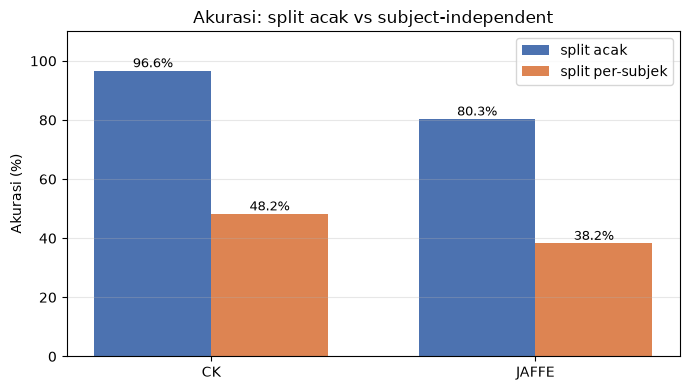

In [21]:
import matplotlib.pyplot as plt

datasets = list(hasil.keys())
x = np.arange(len(datasets))
width = 0.36

acc_random = [hasil[k]["random"]["mean_accuracy"] * 100 for k in datasets]
acc_subject = [hasil[k]["subject"]["mean_accuracy"] * 100 for k in datasets]

fig, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(x - width / 2, acc_random, width, label="split acak", color="#4C72B0")
b2 = ax.bar(x + width / 2, acc_subject, width, label="split per-subjek", color="#DD8452")

for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.2,
                f"{b.get_height():.1f}%", ha="center", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels([k.upper() for k in datasets])
ax.set_ylabel("Akurasi (%)")
ax.set_ylim(0, 110)
ax.set_title("Akurasi: split acak vs subject-independent")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.show()

## 10. Kesimpulan

1. **Artefak noise siap dipakai A2.** Delapan berkas `.npz`
   (`data/a1-noise/`) memuat kunci yang sama dengan artefak praproses A1,
   ditambah metadata `variance` dan `seed`. A2 cukup memanggil
   `extract_features(X)` tanpa mengubah kode apa pun.
2. **σ empiris lebih kecil dari σ teori** karena clipping dan kuantisasi —
   fenomena normal dan sudah dijelaskan di atas.
3. **Kebocoran subjek sangat besar.** Pada CK+, split acak memberi angka yang
   identik dengan hasil A3 Minggu 13, tetapi ketika subjek dipisah dengan benar
   akurasinya turun drastis. Artinya sebagian besar akurasi pada split acak
   berasal dari pengenalan identitas, bukan ekspresi.
4. **Rekomendasi pelaporan:** tampilkan kedua protokol. Angka split acak
   dipakai untuk perbandingan dengan jurnal, sedangkan angka
   **subject-independent** yang diklaim sebagai kemampuan generalisasi.
